# Châssis de drone, sans les bras : première pipeline (v0)

**Question posée** ([CDC_CHASSIS.md](CDC_CHASSIS.md) §1). Le **filtre de surplomb** du solveur
(`topopt/overhang.py`) change-t-il réellement la forme optimale du châssis, et la pièce obtenue est-elle
**imprimable en FDM sans supports** ? C'est ce qui peut justifier un solveur maison face aux outils de design
génératif, qui proposent déjà une contrainte de surplomb ([IDEES_CHASSIS.md](IDEES_CHASSIS.md) §2). Un résultat
négatif est acceptable, à condition d'être documenté tel quel.

**L'expérience.** Trois optimisations identiques en tout (domaine, charges, fraction de matière, filtre de densité,
continuation, point de départ, MMA), sauf un réglage :

| run | filtre de surplomb (45°, axe $z$) | matériau |
|---|---|---|
| **A** | non | PLA FDM orthotrope ($E_z < E_p$) |
| **B** | **oui** | PLA FDM orthotrope |
| **C** | non | PLA isotrope : isole l'effet de l'orthotropie |

**Hors périmètre** : l'aérodynamique (le centre du châssis est hors du souffle des rotors), la fréquence propre, la
résistance (contraintes), les bras eux-mêmes. Les nombres sont **plausibles, pas calés**.

Plan : 1. modélisation · 2. chargements · 3. chaîne de calcul et validation · 4. optimisations A/B/C ·
5. imprimabilité · 6. pièces STL · 7. bilan.

In [1]:
import sys, time, json, math, warnings
from dataclasses import replace
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

ICI = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir()) / "notebooks" / "research" / "chassis"
sys.path.insert(0, str(ICI))
warnings.filterwarnings("ignore", category=UserWarning)

import runs  # réglages des runs A/B/C, cache, optimise(), final()
from runs import RUNS, SCHEDULE, ITS, CACHE, optimise, final, problem
from aeroptimizer.frame import FrameProblem, FrameSetup, LOAD_CASES, MOTOR_SIGNS, MOTOR_SPIN, PLA_FDM, PLA_ISO
from aeroptimizer.fem.adjoint import compliances
from aeroptimizer.fem.solvers import ScipyDirect, AMGCG
from aeroptimizer.fem.bc import rigid_modes
from aeroptimizer.topopt.overhang import OverhangParams
from aeroptimizer.printability import overhang_mask, overhang_rate, support_mask
from aeroptimizer.io.mesh import marching_tetrahedra, mesh_report, smooth_taubin, write_stl, thin_fraction

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
np.set_printoptions(precision=3, suppress=True, linewidth=120)

S = RUNS["A"]
pb = problem("A")
nx, ny, nz = pb.shape
print(f"grille {pb.shape} = {pb.grid.n_elems} éléments de {S.h:g} mm, {pb.op.n_dofs} inconnues ; "
      f"{pb.n_design} variables de conception (un quart, symétries miroir x et y)")

grille (40, 38, 14) = 21280 éléments de 2 mm, 71955 inconnues ; 4104 variables de conception (un quart, symétries miroir x et y)


## 1. Modélisation

**Le drone.** Quadricoptère 5 pouces en X (entraxe moteur-moteur 220 mm), 600 g au décollage, poussée maximale
1,2 kgf par moteur (rapport poussée/poids ≈ 8). Les **bras sont vissés sous le châssis** (2 vis M3 par bras, sur la
diagonale) ; la pile FC/ESC (entraxe 30,5 mm) est posée sur le fond ; la batterie (4S 1300 mAh, 75 × 35 × 35 mm,
180 g) est posée sur le dessus.

**Le domaine de conception** est la boîte 80 × 76 × 28 mm du corps central, imprimée **à plat** : $z$ est à la
fois la verticale du drone et l'**axe de fabrication**, la face $z = 0$ est sur le plateau. C'est le point clé de
l'expérience (CDC §3) : le châssis est réellement 3D selon $z$, avec un étage (la baie de la pile) entre le fond et
le dessus. Une plaque plate n'aurait aucun surplomb, et A = B ne prouverait rien.

**Zones imposées** (masques) :

* **plein** : bossages des vis de bras (sous la face $z = 0$, là où les bras s'appuient), bossages des vis de la pile,
  4 **plots** au coin de la batterie, sur le dessus ;
* **vide** : trous M3 (sur toute la hauteur, accès outil), **baie de la pile** (40 × 40 × 20 mm au-dessus du fond).

**Choix de modélisation.** La batterie repose sur 4 plots, pas sur une plaque pleine. Une plaque au-dessus de la baie
serait un pont de 40 mm : la règle des 45° l'interdit par construction, et le run B n'aurait pas de solution. C'est à
l'optimiseur de décider s'il construit un dessus continu (run A) et comment le soutenir (run B).

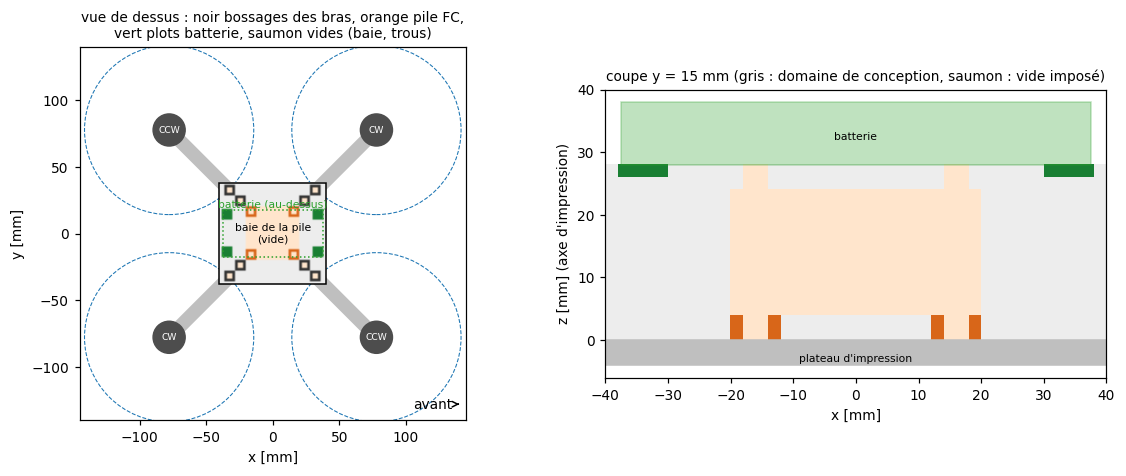

cellules : 16416 libres, 352 pleines imposées, 4512 vides imposées


In [2]:
X, Y, Z = pb.centres()
m = pb.masks
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axs[0]  # vue de dessus
R_mot = S.wheelbase / 2 / math.sqrt(2)
for k, (sx, sy) in enumerate(MOTOR_SIGNS):
    ax.plot([sx * 22, sx * R_mot], [sy * 22, sy * R_mot], color="0.75", lw=9, solid_capstyle="round", zorder=0)
    ax.add_patch(Circle((sx * R_mot, sy * R_mot), 63.5, fill=False, ls="--", color="tab:blue", lw=0.7))
    ax.add_patch(Circle((sx * R_mot, sy * R_mot), 12, color="0.3"))
    ax.text(sx * R_mot, sy * R_mot, "CW" if MOTOR_SPIN[k] < 0 else "CCW", color="w", ha="center", va="center", fontsize=6)
ext = (-S.L / 2, S.L / 2, -S.W / 2, S.W / 2)
carte = np.zeros((nx, ny, 4))
carte[m.design.any(2).numpy()] = (0.93, 0.93, 0.93, 1)
carte[m.void.any(2).numpy() & ~m.solid.any(2).numpy()] = (1.0, 0.9, 0.8, 1)  # colonnes qui traversent un vide imposé
couleurs = {"bras": (0.2, 0.2, 0.2, 1), "fc": (0.85, 0.4, 0.1, 1), "batterie": (0.1, 0.5, 0.2, 1)}
for nom, zone in pb.zones.items():
    carte[zone.any(2)] = couleurs[nom.rstrip("0123")]
ax.imshow(carte.transpose(1, 0, 2), origin="lower", extent=ext, zorder=1)
ax.add_patch(Rectangle((-S.L / 2, -S.W / 2), S.L, S.W, fill=False, color="k", lw=1, zorder=2))
ax.add_patch(Rectangle((-S.battery[0] / 2, -S.battery[1] / 2), S.battery[0], S.battery[1], fill=False, ls=":", color="tab:green", zorder=2))
ax.text(0, S.battery[1] / 2 + 2, "batterie (au-dessus)", color="tab:green", ha="center", fontsize=7)
ax.text(0, 0, "baie de la pile\n(vide)", ha="center", va="center", fontsize=7)
ax.annotate("avant", (140, -128), (105, -128), arrowprops=dict(arrowstyle="->"), va="center")
ax.set(xlim=(-145, 145), ylim=(-140, 140), aspect="equal", xlabel="x [mm]", ylabel="y [mm]",
       title="vue de dessus : noir bossages des bras, orange pile FC,\nvert plots batterie, saumon vides (baie, trous)")
ax = axs[1]  # coupe verticale
j = int(np.argmin(np.abs(Y[0, :, 0] - 15)))  # plan y = 15 mm : bossages de la pile, baie, plots batterie
coupe = np.zeros((nx, nz, 4))
coupe[m.design[:, j].numpy()] = (0.93, 0.93, 0.93, 1)
coupe[m.void[:, j].numpy()] = (1.0, 0.9, 0.8, 1)
for nom, zone in pb.zones.items():
    coupe[zone[:, j]] = couleurs[nom.rstrip("0123")]
ax.imshow(coupe.transpose(1, 0, 2), origin="lower", extent=(-S.L / 2, S.L / 2, 0, S.H))
ax.add_patch(Rectangle((-S.battery[0] / 2, S.H), S.battery[0], 10, color="tab:green", alpha=0.3))
ax.text(0, S.H + 4, "batterie", ha="center", fontsize=7)
ax.add_patch(Rectangle((-S.L / 2 - 5, -4), S.L + 10, 4, color="0.75"))
ax.text(0, -3.4, "plateau d'impression", ha="center", fontsize=7)
ax.set(aspect="equal", ylim=(-6, S.H + 12), xlabel="x [mm]", ylabel="z [mm] (axe d'impression)",
       title=f"coupe y = {Y[0, j, 0]:.0f} mm (gris : domaine de conception, saumon : vide imposé)")
plt.tight_layout(); plt.show()
print(f"cellules : {int(m.design.sum())} libres, {int(m.solid.sum())} pleines imposées, {int(m.void.sum())} vides imposées")

**Matériau.** PLA imprimé, isotrope transverse autour de $z$ : $E_p$ = 3,3 GPa dans le plan des couches,
$E_z$ = 2,3 GPa entre les couches (≈ 70 %, ordre de grandeur des essais publiés, **non calé** sur notre imprimante),
$G_z$ = 0,9 GPa, $\nu$ = 0,33. Le run C utilise le PLA isotrope ($E$ = 3,3 GPa partout).

**Fraction de matière** : 20 % des cellules libres. Avec les zones imposées, cela fait environ 35 g de PLA, la masse
d'un corps de châssis 5" imprimé.

## 2. Chargements : la dynamique du drone, sans encastrement

Un drone en vol n'est **encastré nulle part** : les charges sur le châssis s'équilibrent entre elles. Encastrer
arbitrairement une zone fausserait l'optimisation, qui renforcerait le chemin vers cet appui fictif.

**Méthode.**

1. Le drone est un ensemble de corps rigides : 4 « unités bras » (bras + moteur + hélice, 50 g, au moteur), la
   batterie (180 g, boîte 75 × 35 × 35 mm au-dessus du châssis), la pile (220 g : électronique, caméra, câbles et le
   châssis lui-même, boîte de la baie). Le châssis sert de liaison entre ces corps ; sa propre masse est comptée
   dans celle de la pile.
2. Pour un cas de vol (les poussées $T_k$ des 4 moteurs et leurs couples de réaction $Q_k = \mp k_Q T_k$,
   $k_Q$ = 12 mm), on calcule par Newton–Euler l'accélération linéaire $\mathbf a$ et angulaire $\boldsymbol\alpha$
   du drone au **début** de la manœuvre (vitesse de rotation nulle) :
   $M\mathbf a = \sum \mathbf T_k + M\mathbf g$, $\;\mathbf I_G\,\boldsymbol\alpha = \sum (\mathbf p_k - \mathbf c)\times\mathbf T_k + \sum\mathbf Q_k$.
3. Chaque corps transmet au châssis ses efforts extérieurs, son poids et sa force d'inertie de d'Alembert,
   $\mathbf F_i = \mathbf T_i + m_i\mathbf g - m_i[\mathbf a + \boldsymbol\alpha\times(\mathbf p_i - \mathbf c)]$ et
   $\mathbf M_i = \mathbf Q_i - \mathbf I_i\boldsymbol\alpha$, réparti sur ses nœuds d'interface comme un patch rigide
   (bossages des bras sous la face inférieure, dessus des bossages de la pile, dessus des plots batterie).
4. La somme est nulle **exactement**. Trois appuis ponctuels isostatiques (3-2-1) suppriment les 6 mouvements de
   corps rigide sans rien porter : la compliance ne dépend pas de l'endroit où ils sont (vérifié au § 3).

**Les cas de charge** (une seule matrice de rigidité, 4 seconds membres) :

| cas | moteurs à pleine poussée | les autres à 10 % | ce qu'il sollicite |
|---|---|---|---|
| `poussee` | les 4 | | flexion du fond entre les bras, inertie de la batterie (≈ 7 g) |
| `roulis` | les 2 de gauche | les 2 de droite | flexion transverse, inertie en rotation |
| `tangage` | les 2 arrière | les 2 avant | flexion longitudinale |
| `lacet` | les 2 qui tournent en sens horaire (diagonale) | l'autre diagonale | **torsion** du châssis (poussées diagonales) + couples des hélices |

Un atterrissage brutal à plat charge les mêmes chemins que `poussee` (les bras poussent vers le haut, la batterie
vers le bas), avec un facteur de charge du même ordre : il n'est pas ajouté.

**Objectif** : $J = \frac14\sum_k C_k / C_k^{\rm ref}$, à volume fixé. La référence est la même masse **étalée
uniformément** (densité 0,2 partout, sans pénalisation) : elle ne sert qu'à mettre les 4 cas à la même échelle, pour
que des poids égaux veuillent dire « importance égale ».

In [3]:
print(f"{'cas':9s} {'a_z [g]':>8s} {'alpha [rad/s²]':>26s} {'résultante |F| [N]':>19s} {'|M| [N mm]':>11s} {'C_ref [N mm]':>13s}")
R = pb.resultant()
for k, c in enumerate(pb.cases):
    a, al = pb.kinematics[c]
    print(f"{c:9s} {a[2] / 9.81:8.2f} {str(al.round(0)):>26s} {np.linalg.norm(R[k, :3]):19.1e} {np.linalg.norm(R[k, 3:]):11.1e} {pb.refs[c]:13.3f}")
F = pb.f.numpy().reshape(-1, 3, len(pb.cases))
print(f"\nefforts totaux transmis (somme des |F| nodaux) : " + ", ".join(f"{c} {np.abs(F[..., k]).sum():.0f} N" for k, c in enumerate(pb.cases)))

cas        a_z [g]             alpha [rad/s²]  résultante |F| [N]  |M| [N mm]  C_ref [N mm]
poussee       7.02                 [0. 0. 0.]             1.2e-12     5.5e-12         3.477
roulis        3.41        [1113.    0.    0.]             7.2e-13     4.0e-12         1.099
tangage       3.41        [  -0. 1065.    0.]             7.3e-13     8.6e-12         1.225
lacet         3.41              [-0. -0. 99.]             7.2e-13     6.2e-12         3.066

efforts totaux transmis (somme des |F| nodaux) : poussee 436 N, roulis 249 N, tangage 270 N, lacet 280 N


Les résultantes sont nulles à la précision machine. En poussée maximale, le drone accélère vers le haut à 7 g : la
batterie pèse alors 8 fois son poids sur ses plots. Les accélérations angulaires (~1 000 rad/s² en roulis et en
tangage) sont celles d'un drone de course qui bascule en quelques dixièmes de seconde.

## 3. La chaîne de calcul et sa validation

| étape | opération | module |
|---|---|---|
| 1. symétrie | $x$ décrit un quart du châssis ($x \ge 0$, $y \ge 0$), miroirs en $x$ et $y$ (densité seulement : les charges restent asymétriques) | `frame.FrameProblem.expand` |
| 2. filtre | moyenne conique, rayon $R$ = 3 mm (1,5 maille) | `topopt/density.py` |
| 3. projection | $\tanh$, netteté $\beta$ = 1 → 16 (doublée toutes les 25 itérations) | `topopt/density.py` |
| 4. surplomb (run B) | balayage couche par couche selon $z$ ; toute matière doit reposer sur la couche du dessous dans une croix de 5 cellules (45°) ; netteté $\beta_s$ = 10 → 80 (Langelaar 2017) | `topopt/overhang.py` |
| 5. masques | plein / vide imposés, réappliqués après filtrage | `DensityPipeline` |
| 6. rigidité | SIMP $E = E_{\min} + (1 - E_{\min})\,\bar\rho^3\,\mathbf C_0$, $\mathbf C_0$ orthotrope ; hexaèdres Q1 (2 mm) | `fem/` |
| 7. résolution | gradient conjugué préconditionné par multigrille algébrique (pyamg), 4 cas | `fem/solvers.AMGCG` |
| 8. compliance | $C_k = \mathbf f_k^\top\mathbf u_k$ ; auto-adjointe : $\partial C_k/\partial w_e = -\mathbf u_{k,e}^\top\mathbf K^0_e\mathbf u_{k,e}$, **aucune résolution adjointe** | `fem/adjoint.compliances` |
| 9. optimiseur | MMA (Svanberg 1987), contrainte de volume, 150 itérations | `optim/` |

**Pourquoi un solveur itératif.** Avec 72 000 inconnues en 3D, la factorisation directe de SciPy (SuperLU) dépasse
2 minutes par itération. Le multigrille algébrique (agrégation lissée, modes rigides comme espace quasi nul) résout
les 4 cas en ~8 s sur un portable, en 20 à 30 itérations de gradient conjugué tant que le design est d'un seul
tenant. Limite connue : chaque îlot de matière flottant dans le quasi-vide ajoute des valeurs propres quasi nulles,
et le nombre d'itérations grimpe (cf. § 7).

**Validation** sur une grille grossière (mailles de 4 mm), contre le solveur direct.

In [4]:
petit = FrameSetup(L=80.0, W=80.0, H=28.0, h=4.0, R=6.0, pad_height=4.0)
pbs = FrameProblem(petit, solver=ScipyDirect())
w = 0.1 + torch.rand(pbs.grid.n_elems)
C_lu, _ = compliances(pbs.op, w, pbs.f, ScipyDirect())
C_amg, _ = compliances(pbs.op, w, pbs.f, AMGCG(tol=1e-10))
print("multigrille vs direct, écart relatif par cas :", ", ".join(f"{v:.1e}" for v in ((C_amg - C_lu) / C_lu).numpy()))
print(f"travail des charges sur les 6 modes rigides     : {np.abs((rigid_modes(pbs.grid).T @ pbs.f).numpy()).max():.1e}")

for nom, ovh in (("sans surplomb", None), ("avec surplomb", OverhangParams())):
    p = FrameProblem(replace(petit, overhang=ovh), solver=ScipyDirect(), refs=pbs.refs)
    p.set_continuation({"p": 3.0, "beta": 2.0, "beta_s": 10.0})
    x0 = torch.from_numpy(p.initial_design()) + 0.1 * torch.rand(p.n_design)
    d, e = torch.randn_like(x0), 1e-5
    x = x0.clone().requires_grad_()
    (g,) = torch.autograd.grad(p.evaluate(x).J, x)
    with torch.no_grad():
        fd = (p.evaluate(x0 + e * d).J - p.evaluate(x0 - e * d).J) / (2 * e)
    print(f"{nom:14s} dJ/dx · d : adjoint = {float(g @ d):+.10e}   différences finies = {float(fd):+.10e}")

multigrille vs direct, écart relatif par cas : 2.3e-15, 2.0e-15, 1.6e-15, 1.5e-14
travail des charges sur les 6 modes rigides     : 1.8e-11


sans surplomb  dJ/dx · d : adjoint = +4.0975235178e-01   différences finies = +4.0975232398e-01


avec surplomb  dJ/dx · d : adjoint = +1.9370976627e+01   différences finies = +1.9370976511e+01


Le multigrille donne les mêmes compliances que la factorisation directe, les charges ne travaillent sur aucun
mouvement de corps rigide (donc les appuis 3-2-1 ne portent rien), et le gradient de toute la chaîne (y compris le
balayage du filtre de surplomb) coïncide avec les différences finies. `pytest tests/unit/test_frame.py` refait ces
contrôles, plus l'indépendance de la compliance vis-à-vis de l'emplacement des appuis.

## 4. Optimisations A, B, C

Les trois runs sont calculés par `runs.py` (en parallèle, ~40 min sur un portable) et mis en cache dans `results/`.
Relancer : `python notebooks/research/chassis/runs.py A B C --force`.

run A : J = 0.812  [poussee 0.741, roulis 0.844, tangage 0.841, lacet 0.822]  masse 36.1 g  vol 0.200  (150 it., 32 min)


run B : J = 1.318  [poussee 1.205, roulis 1.219, tangage 1.289, lacet 1.560]  masse 36.1 g  vol 0.200  (150 it., 35 min)


run C : J = 0.847  [poussee 0.771, roulis 0.881, tangage 0.885, lacet 0.852]  masse 36.1 g  vol 0.200  (150 it., 33 min)


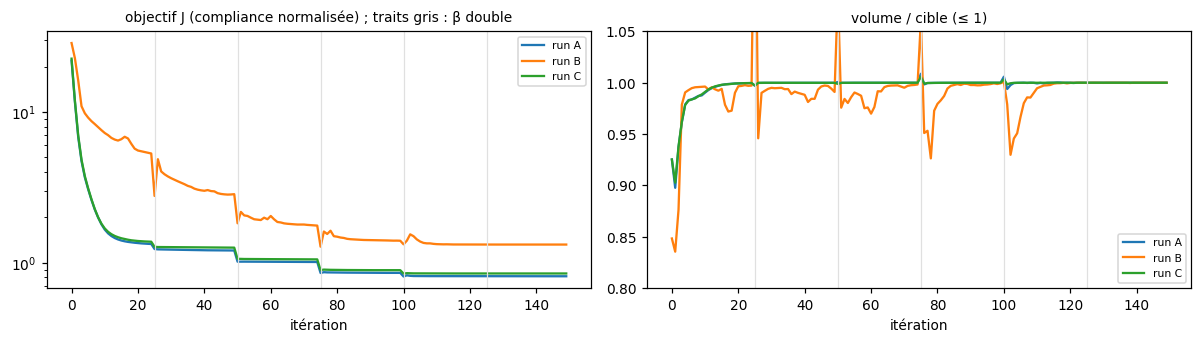

In [5]:
pbs_run = {"A": pb, "B": problem("B", refs=pb.refs), "C": problem("C")}  # C : références de son propre matériau
X_run, res, hist = {}, {}, {}
for nom in RUNS:
    X_run[nom], hist[nom] = optimise(nom)
    res[nom], h = final(pbs_run[nom], X_run[nom]), hist[nom]
    t = res[nom].terms
    print(f"run {nom} : J = {float(t['C_hat']):.3f}  [" + ", ".join(f"{c} {float(t[f'C_{c}_hat']):.3f}" for c in pb.cases)
          + f"]  masse {float(t['masse']):.1f} g  vol {float(t['vol']):.3f}  ({len(h)} it., {sum(r['t_it'] for r in h) / 60:.0f} min)")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
for nom, h in hist.items():
    it = [r["it"] for r in h]
    axs[0].semilogy(it, [r["J"] for r in h], label=f"run {nom}")
    axs[1].plot(it, [r["vol"] / S.volfrac for r in h], label=f"run {nom}")
for ax in axs:
    for k in range(SCHEDULE.every, ITS, SCHEDULE.every):
        ax.axvline(k, color="0.88", lw=0.8)
    ax.set_xlabel("itération"); ax.legend(fontsize=7)
axs[0].set(title="objectif J (compliance normalisée) ; traits gris : β double")
axs[1].set(title="volume / cible (≤ 1)", ylim=(0.8, 1.05))
plt.tight_layout(); plt.show()

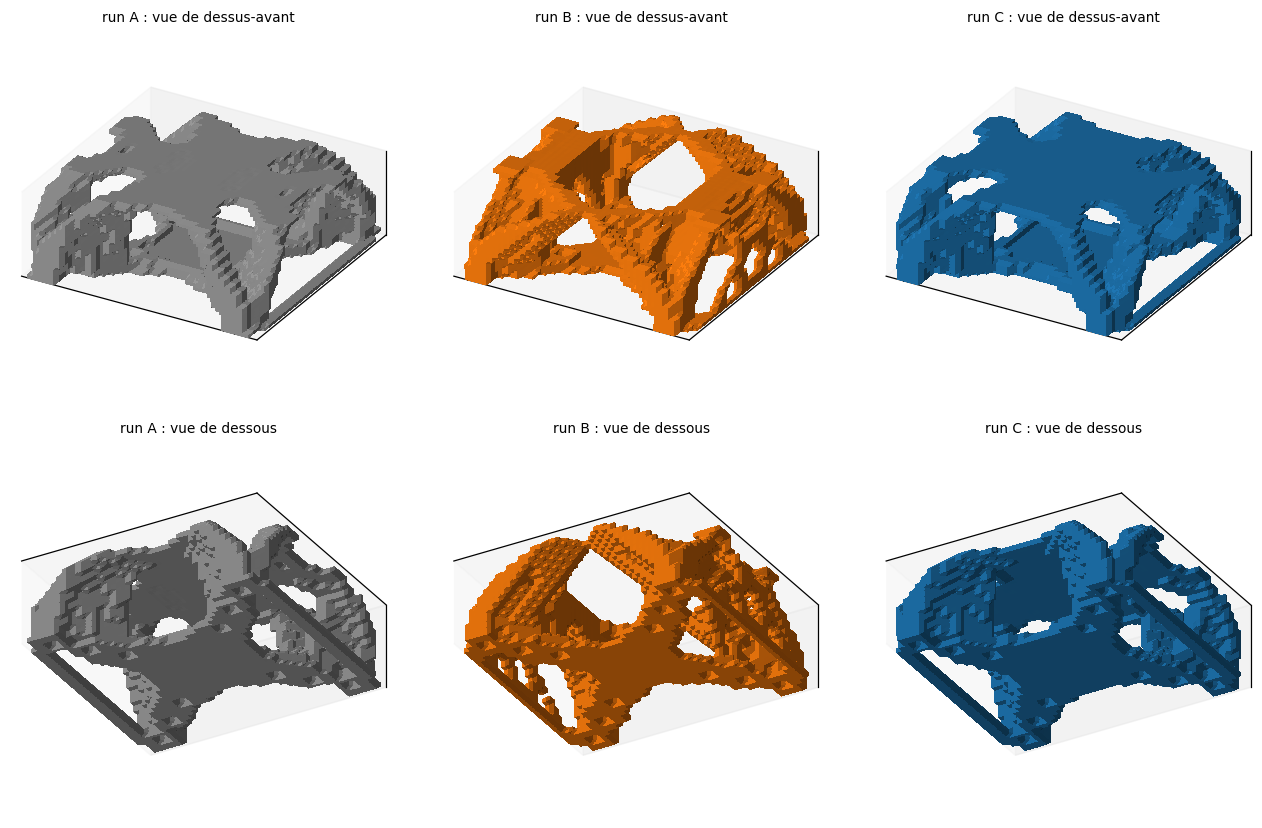

In [6]:
def rendu(ax, rho, titre, couleur="tab:orange", elev=28, azim=-60):
    V, F = marching_tetrahedra(np.asarray(rho), 0.5, (S.h,) * 3)
    V = V - np.array([S.L / 2, S.W / 2, 0.0])
    ax.plot_trisurf(V[:, 0], V[:, 1], F, V[:, 2], color=couleur, linewidth=0, shade=True, antialiased=False)
    ax.set_proj_type("ortho"); ax.set_box_aspect((S.L, S.W, S.H)); ax.view_init(elev=elev, azim=azim)
    ax.set(xlim=(-S.L / 2, S.L / 2), ylim=(-S.W / 2, S.W / 2), zlim=(0, S.H))
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title(titre)


rho = {nom: r.state[0].numpy() for nom, r in res.items()}
couleur = {"A": "0.6", "B": "tab:orange", "C": "tab:blue"}
fig = plt.figure(figsize=(12, 7.6))
for j, nom in enumerate(RUNS):
    rendu(fig.add_subplot(2, 3, j + 1, projection="3d"), rho[nom], f"run {nom} : vue de dessus-avant", couleur[nom])
    rendu(fig.add_subplot(2, 3, j + 4, projection="3d"), rho[nom], f"run {nom} : vue de dessous", couleur[nom], elev=-30)
plt.tight_layout(); plt.show()

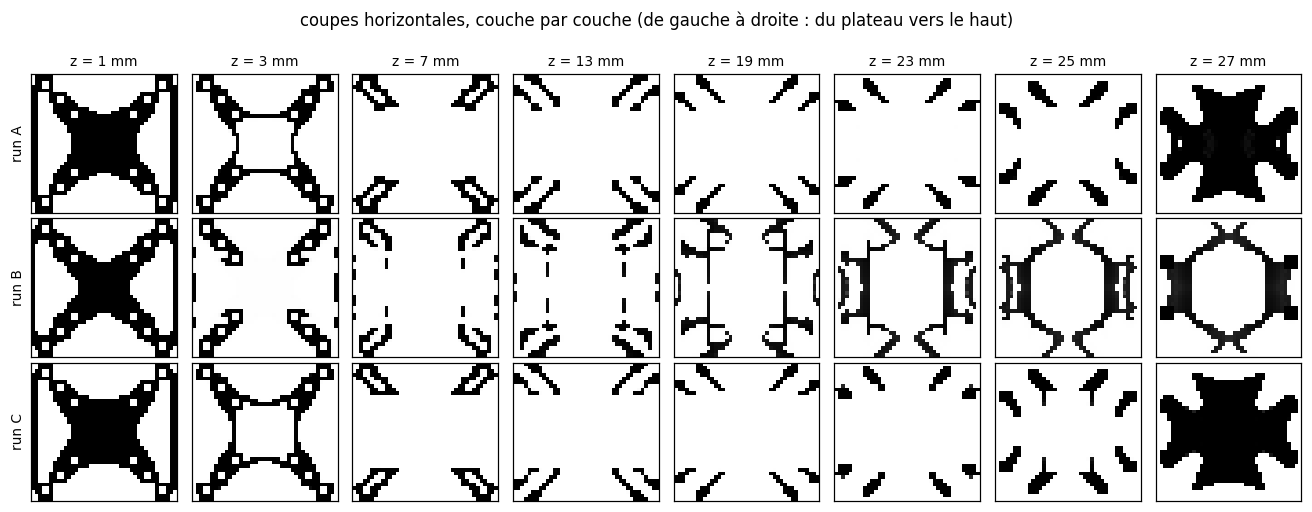

In [7]:
niveaux = [0, 1, 3, 6, 9, 11, 12, 13]  # couches (z = 2k + 1 mm)
fig, axs = plt.subplots(len(RUNS), len(niveaux), figsize=(12, 4.6))
for i, nom in enumerate(RUNS):
    for j, k in enumerate(niveaux):
        ax = axs[i, j]
        ax.imshow(rho[nom][:, :, k].T, origin="lower", cmap="gray_r", vmin=0, vmax=1, extent=(-S.L / 2, S.L / 2, -S.W / 2, S.W / 2))
        ax.set(xticks=[], yticks=[])
        if i == 0:
            ax.set_title(f"z = {2 * k + 1} mm")
        if j == 0:
            ax.set_ylabel(f"run {nom}")
fig.suptitle("coupes horizontales, couche par couche (de gauche à droite : du plateau vers le haut)", y=1.0)
plt.tight_layout(); plt.show()

## 5. Imprimabilité

Mesures voxel (`printability.py`, indépendantes du filtre : elles jugent A comme B), sur la pièce seuillée
$\bar\rho > 0{,}5$ :

* **taux de surplomb** : fraction des voxels pleins (hors plateau et hors zones imposées) qui ne reposent sur rien
  dans la couche du dessous. Règle stricte « croix » = 45°, celle du filtre ; règle « 3 × 3 », plus tolérante
  (pas diagonal ≈ 55°) ;
* **volume de supports** : les colonnes vides qu'un trancheur remplirait sous chaque voxel en surplomb, jusqu'au
  plateau ou à la pièce ;
* **parois fines** : part de la matière où une boule de rayon 1 maille (diamètre ~6 mm) ne passe pas
  (`io.mesh.thin_fraction`) ; à 2 mm de maille, c'est surtout un indicateur de finesse relative.

Aucun trancheur en ligne de commande n'est installé sur la machine : le volume de supports voxel en tient lieu.
Le test final reste l'impression (CDC §2).

In [8]:
tab = {}
for nom in RUNS:
    solide = rho[nom] > 0.5
    passif = pb.masks.solid.numpy()
    t = res[nom].terms
    sup = support_mask(solide)
    tab[nom] = {
        "J": float(t["C_hat"]), **{c: float(t[f"C_{c}_hat"]) for c in pb.cases}, "masse [g]": float(t["masse"]),
        "surplomb croix [%]": 100 * overhang_rate(solide, ignore=passif),
        "surplomb 3×3 [%]": 100 * overhang_rate(solide, ignore=passif, stencil="square"),
        "supports [cm³]": sup.sum() * S.h**3 / 1e3,
        "supports / pièce [%]": 100 * sup.sum() / solide.sum(),
        "plots suspendus": int((overhang_mask(solide) & passif).sum()),
        "parois fines [%]": 100 * thin_fraction(solide, 1.0),
        "itérations": len(hist[nom]), "temps [min]": sum(r["t_it"] for r in hist[nom]) / 60,
    }
cles = list(tab["A"])
print(f"{'':22s}" + "".join(f"{'run ' + n:>11s}" for n in RUNS))
for k in cles:
    print(f"{k:22s}" + "".join(f"{tab[n][k]:11.3f}" if isinstance(tab[n][k], float) else f"{tab[n][k]:11d}" for n in RUNS))

                            run A      run B      run C
J                           0.812      1.318      0.847
poussee                     0.741      1.205      0.771
roulis                      0.844      1.219      0.881
tangage                     0.841      1.289      0.885
lacet                       0.822      1.560      0.852
masse [g]                  36.061     36.059     36.061
surplomb croix [%]         20.146      0.000     20.968
surplomb 3×3 [%]           18.540      0.000     19.501
supports [cm³]             55.328      0.416     57.152
supports / pièce [%]      190.000      1.392    196.264
plots suspendus                20          4         20
parois fines [%]           67.473     70.343     68.681
itérations                    150        150        150
temps [min]                32.082     35.425     32.844


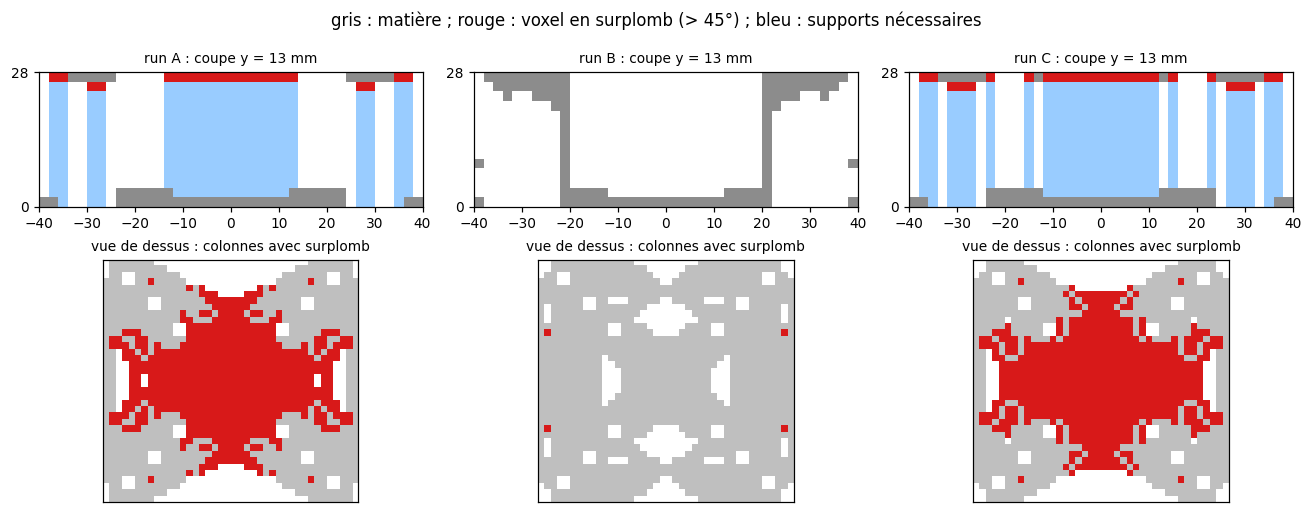

In [9]:
# où sont les surplombs ? coupe verticale par le plan des plots batterie, et projection de dessus
j = int(np.argmin(np.abs(Y[0, :, 0] - 13)))
fig, axs = plt.subplots(2, len(RUNS), figsize=(12, 4.6), gridspec_kw={"height_ratios": [1, 1.6]})
for i, nom in enumerate(RUNS):
    solide = rho[nom] > 0.5
    hang, sup = overhang_mask(solide), support_mask(solide)
    img = np.ones((nx, nz, 3))
    img[solide[:, j]] = (0.55, 0.55, 0.55)
    img[sup[:, j]] = (0.6, 0.8, 1.0)
    img[hang[:, j]] = (0.85, 0.1, 0.1)
    axs[0, i].imshow(img.transpose(1, 0, 2), origin="lower", extent=(-S.L / 2, S.L / 2, 0, S.H))
    axs[0, i].set(title=f"run {nom} : coupe y = {Y[0, j, 0]:.0f} mm", yticks=[0, S.H])
    vue = np.ones((nx, ny, 3))
    vue[solide.any(2)] = (0.75, 0.75, 0.75)
    vue[sup.any(2)] = (0.6, 0.8, 1.0)
    vue[hang.any(2)] = (0.85, 0.1, 0.1)
    axs[1, i].imshow(vue.transpose(1, 0, 2), origin="lower", extent=(-S.L / 2, S.L / 2, -S.W / 2, S.W / 2))
    axs[1, i].set(title="vue de dessus : colonnes avec surplomb", xticks=[], yticks=[])
fig.suptitle("gris : matière ; rouge : voxel en surplomb (> 45°) ; bleu : supports nécessaires", y=1.0)
plt.tight_layout(); plt.show()

### 5.1 Le coût de l'orthotropie et du filtre, en croisé

Pour séparer les effets, on réévalue les formes A et C avec l'autre matériau : la forme C (dessinée pour un
matériau isotrope) est-elle moins bonne que A une fois imprimée en vrai PLA orthotrope ? (B n'entre pas dans ce
tableau : sa forme n'existe qu'à travers son filtre de surplomb.)

In [10]:
print(f"{'':10s}{'matériau réel : PLA orthotrope':>34s}{'matériau idéal : PLA isotrope':>34s}")
for nom in ("A", "C"):
    J = [float(final(p, X_run[nom]).terms["C_hat"]) for p in (pbs_run["A"], pbs_run["C"])]
    print(f"forme {nom:4s}{J[0]:34.4f}{J[1]:34.4f}")
print("(J normalisé par la référence du même matériau ; plus bas = plus raide)")

              matériau réel : PLA orthotrope     matériau idéal : PLA isotrope


forme A                               0.8118                            0.8408


forme C                               0.8258                            0.8473
(J normalisé par la référence du même matériau ; plus bas = plus raide)


## 6. Pièces imprimables

Surfaces fermées à $\bar\rho = 0{,}5$ (tétraèdres marchants), lissées (Taubin, volume conservé, faces de la boîte
gardées planes), en mm, prêtes pour un trancheur. Les trous M3 sont modélisés par des carrés de 4 mm (une maille
autour de l'axe) : à reprendre au foret de 3,2 mm.

In [11]:
for nom in RUNS:
    V, F = marching_tetrahedra(rho[nom], 0.5, (S.h,) * 3)
    lo, hi = np.zeros(3), np.array([S.L, S.W, S.H])
    V = smooth_taubin(V, F, iterations=10, box=(lo, hi)) - np.array([S.L / 2, S.W / 2, 0.0])
    rep = mesh_report(V, F)
    write_stl(CACHE / f"frame_{nom}.stl", V, F, name=f"frame_{nom}")
    print(f"frame_{nom}.stl : {rep['n_faces']} triangles, étanche {rep['watertight']}, "
          f"volume {rep['volume'] / 1e3:.1f} cm³ ({rep['volume'] * 1.24e-3:.0f} g de PLA), "
          f"caractéristique d'Euler {rep['euler']}")

frame_A.stl : 45680 triangles, étanche True, volume 28.2 cm³ (35 g de PLA), caractéristique d'Euler -82
frame_B.stl : 49004 triangles, étanche True, volume 27.9 cm³ (35 g de PLA), caractéristique d'Euler -168


frame_C.stl : 45936 triangles, étanche True, volume 28.2 cm³ (35 g de PLA), caractéristique d'Euler -70


## 7. Bilan

**En trois phrases** (critère de fin du CDC §7) :

1. **Le filtre a un effet, et il est fort.** Sans lui (A, C), l'optimiseur referme le dessus du châssis par une
   **plaque pleine posée au-dessus de la baie de la pile**, portée par de fins piliers : c'est le caisson fermé qui
   reprend le mieux la torsion. Imprimée à plat, cette plaque est en surplomb sur toute sa surface. Avec le filtre
   (B), la plaque disparaît : des **parois inclinées à 45°** partent des bossages du fond et convergent vers les plots
   de la batterie, et le dessus devient un anneau ouvert.
2. **Le coût est de +62 % de compliance** à masse égale (J = 1,32 contre 0,81). Il est le plus fort en **lacet**
   (+90 %), le cas de torsion, justement celui qui profitait du caisson fermé.
3. **B est imprimable presque sans supports** : 0,4 cm³ (1,4 % du volume de la pièce) contre 55 cm³ pour A
   (190 %), soit plus de 100 fois moins. Le reste vient des seuls coins extérieurs des 4 plots batterie imposés, que
   les masques remettent après le filtre (à chanfreiner dans la géométrie imposée).

**L'orthotropie, elle, change peu ce châssis** (§ 5.1) : la forme C, dessinée en isotrope, n'est que ~2 % plus
souple que A une fois évaluée en PLA orthotrope, et A et C se ressemblent beaucoup. Ici la matière travaille surtout
dans le plan des couches ; l'argument du solveur maison repose donc sur le **surplomb**, pas sur l'orthotropie.

### Ce qu'il faut dire en présentant (limites)

| limite | effet | piste |
|---|---|---|
| la règle des 45° interdit les **ponts** | un trancheur sait imprimer un pont horizontal de quelques centimètres entre deux appuis : la plaque de A est peut-être imprimable sans supports, en pont. Le volume de supports de A (55 cm³) est donc un **majorant** | imprimer A et B (test final du CDC) ; **[idée]** un filtre qui tolère les ponts courts entre deux appuis |
| grille de 2 mm | parois de 1 à 2 mailles ; « parois fines » ~70 % au sens d'une boule de 6 mm | maillage plus fin (le multigrille le permet, au prix du temps de calcul) |
| raideur, pas résistance | pas de contrainte de rupture ni de délaminage entre couches, qui est justement le point faible de B (parois inclinées sollicitées entre couches ?) | critère de Hill (`materials.hill_index`) agrégé en $P$-norme |
| charges quasi statiques | début de manœuvre, pas de choc ni de vibration | fréquence propre (IDEES §3), choc |
| bras absents | les bras sont des corps rigides qui transmettent poussée et couple | v2 : bras + châssis d'un seul tenant |
| multigrille non robuste aux îlots | ~20 itérations de CG ici ; un design avec beaucoup d'îlots flottants en demanderait des centaines | multigrille géométrique adapté au contraste (Amir et al. 2014) |
| matériau non calé | $E_z/E_p$ = 0,7 supposé | éprouvettes sur notre imprimante (IDEES §5) |

### Suite proposée

1. **Imprimer B, et A en parallèle** : B doit sortir sans supports ; A dira si la plaque passe en pont.
2. Run de **référence Fusion** (Additive, 45°), même domaine, mêmes charges et même masse, à comparer à B en
   compliance et en volume de supports (IDEES §2).
3. Contrainte de résistance entre couches, puis fréquence propre.